# BioGuard-X — Notebook 02: Fingerprint Bonus (Offline Upload Only)

**Traditional Machine Learning, no CNN / no Deep Learning.** This notebook is fully separate from the already executed RAVDESS Master Notebook. **It does NOT retrain face/voice/video models.**

**Goal:** image fingerprint verification (same physical finger = Genuine, different physical finger = Impostor). Pipeline: Dataset Exploration → Grayscale/Histogram Equalization/Resize → Sobel + LBP (29-dimensional feature vector) → SVM / Random Forest → Validation selection → Held-out test, FAR, FRR, Confusion Matrices, ROC → `.joblib` Export → OFFLINE upload test. Only **training & uploaded-image demo**, as requested by the instructor.

**Data:** [SOCOFing on Kaggle](https://www.kaggle.com/datasets/ruizgara/socofing) — keep ZIP compressed in Downloads, filename must contain `socofing`; or extract into `Downloads/SOCOFing`. You may choose the real ZIP path explicitly. No need to download anything to RAVDESS's folders.

**Methodological note:** the source includes artificially altered copies of original scans. We hold out subjects across splits, but this is **not** an independent live-scan benchmark. Do not claim medical/security grade accuracy.

## 1 — Setup, dataset path and imports

**Only run this notebook from the project directory** `Downloads/BioGuard_Task2_COMPLETE` using the existing **Python (BioGuard Task 2)** kernel. The additional Python file `fingerprint_research.py` must be alongside it. The `model/` directory is shared with the original RAVDESS notebook; the existing model is never overwritten.

In [1]:
from pathlib import Path
import time, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2, joblib
from skimage.feature import local_binary_pattern
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, roc_curve, classification_report
from IPython.display import display
import bioguard_core as core
import fingerprint_research as fp

FP_SOURCE = None  # None => searches Downloads for *socofing*.zip or Downloads/SOCOFing folder
FP_MAX_FINGERS = 120  # Increase later to 300+ if you have enough RAM/time
FP_MAX_ALTERATIONS = 3
OUT = Path('outputs') / 'fingerprint_bonus'; OUT.mkdir(parents=True,exist_ok=True)
MODEL = Path('model'); MODEL.mkdir(parents=True,exist_ok=True)
print('Python:', sys.executable)
print('SOCOFing source:', fp._source(FP_SOURCE))
print('Public RAVDESS model unchanged:', (MODEL/'public_models.joblib').exists())

Python: c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Scripts\python.exe
SOCOFing source: <PROJECT_ROOT>\Downloads\socofing.zip
Public RAVDESS model unchanged: True


## 2 — Dataset Exploration (BEFORE training)

`finger` is not person ID alone: it combines **subject, hand, finger**. Left thumb and right thumb are different fingerprint identities. Some SOCOFing scans include synthetic alterations with names such as CR, OBL, ZCUT. We build a controlled subset for a laptop.

SOCOFing: 120 fingers, 480 images; source=<PROJECT_ROOT>\Downloads\socofing.zip
Images: 480 Finger IDs: 120 Subjects: 110


col_0,Number of images
kind,
altered,360
real,120


,finger,kind,path,source
0,547__m_right_thumb_finger,real,fingerprint_data\selected\real\26b33b47a1a2_00...,socofing/SOCOFing/Real/547__M_Right_thumb_fing...
1,547__m_right_thumb_finger,altered,fingerprint_data\selected\altered\26b33b47a1a2...,SOCOFing/Altered/Altered-Easy/547__M_Right_thu...
2,547__m_right_thumb_finger,altered,fingerprint_data\selected\altered\26b33b47a1a2...,SOCOFing/Altered/Altered-Easy/547__M_Right_thu...
3,547__m_right_thumb_finger,altered,fingerprint_data\selected\altered\26b33b47a1a2...,SOCOFing/Altered/Altered-Easy/547__M_Right_thu...
4,40__f_left_index_finger,real,fingerprint_data\selected\real\e40206653c1a_00...,socofing/SOCOFing/Real/40__F_Left_index_finger...
5,40__f_left_index_finger,altered,fingerprint_data\selected\altered\e40206653c1a...,SOCOFing/Altered/Altered-Easy/40__F_Left_index...
6,40__f_left_index_finger,altered,fingerprint_data\selected\altered\e40206653c1a...,SOCOFing/Altered/Altered-Easy/40__F_Left_index...
7,40__f_left_index_finger,altered,fingerprint_data\selected\altered\e40206653c1a...,SOCOFing/Altered/Altered-Easy/40__F_Left_index...
8,280__m_left_little_finger,real,fingerprint_data\selected\real\31466abdbaf9_00...,socofing/SOCOFing/Real/280__M_Left_little_fing...
9,280__m_left_little_finger,altered,fingerprint_data\selected\altered\31466abdbaf9...,SOCOFing/Altered/Altered-Easy/280__M_Left_litt...


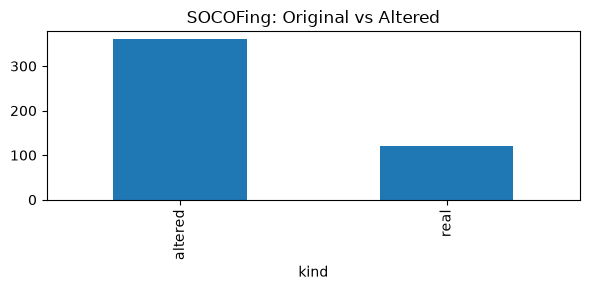

In [2]:
fp_manifest=fp.prepare_socofing(source=FP_SOURCE,max_fingers=FP_MAX_FINGERS,max_alterations=FP_MAX_ALTERATIONS,
                                   output='fingerprint_data/selected',seed=42)
print('Images:',len(fp_manifest),'Finger IDs:',fp_manifest.finger.nunique(),
      'Subjects:',fp_manifest.finger.map(lambda x:x.split('__')[0]).nunique())
display(pd.crosstab(fp_manifest.kind,columns='Number of images'))
display(fp_manifest.head(10))
fig, ax=plt.subplots(figsize=(6,3))
fp_manifest.kind.value_counts().plot.bar(ax=ax);ax.set_title('SOCOFing: Original vs Altered');plt.tight_layout()
plt.savefig(OUT/'01_dataset_distribution.png',dpi=160);plt.show()

## 3 — Fingerprint preprocessing: Grayscale, Equalization, Sobel, LBP

**Sobel:** calculates horizontal and vertical image gradients, then gradient magnitude/orientation to describe ridge edges. **LBP:** compares each center pixel to its 8 neighbors, generating a binary pattern; a normalized histogram summarizes the textures. **29 D total:** Sobel orientation histogram 16 + uniform LBP 10 + Sobel statistics 3. This is feature extraction **not** neural learning.

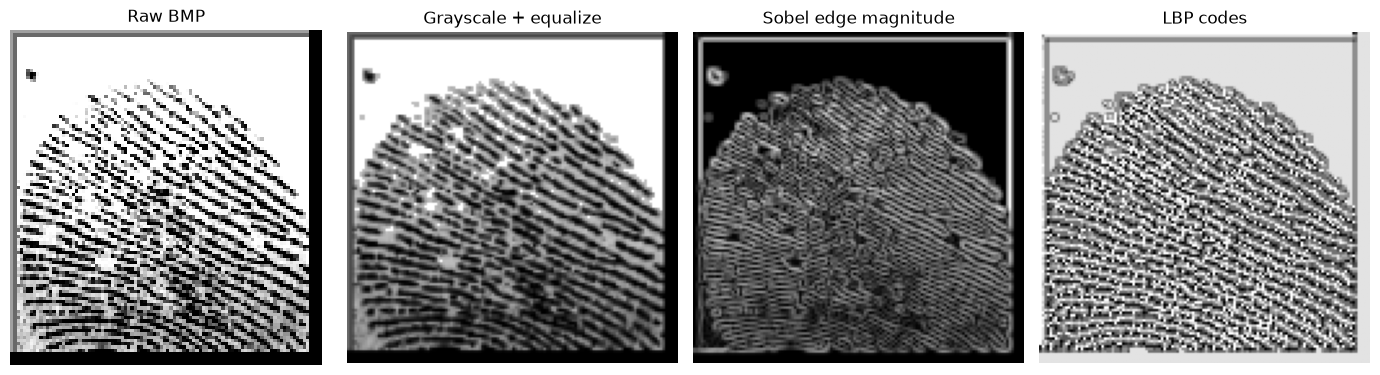

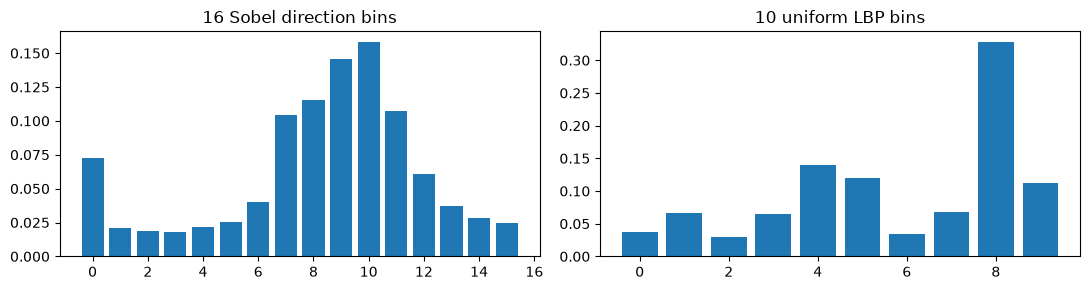

Feature vector dimension: 29


In [3]:
example=fp_manifest.query("kind=='real'").iloc[0]
raw=cv2.imread(str(example.path),cv2.IMREAD_GRAYSCALE)
assert raw is not None, 'Sample fingerprint could not be loaded'
g=cv2.equalizeHist(cv2.resize(raw,(128,128)))
gx=cv2.Sobel(g.astype('float32')/255,cv2.CV_32F,1,0,ksize=3)
gy=cv2.Sobel(g.astype('float32')/255,cv2.CV_32F,0,1,ksize=3)
mag=cv2.magnitude(gx,gy)
lbp=local_binary_pattern(g,8,1,method='uniform')
fig,axs=plt.subplots(1,4,figsize=(14,3.7))
for ax,label,img in zip(axs,['Raw BMP','Grayscale + equalize','Sobel edge magnitude','LBP codes'],[raw,g,mag,lbp]):
    ax.imshow(img,cmap='gray');ax.set_title(label);ax.axis('off')
plt.tight_layout();plt.savefig(OUT/'02_sobel_lbp_images.png',dpi=160);plt.show()
vec=core.extract_fingerprint(example.path)
assert vec.shape==(29,)
fig,axs=plt.subplots(1,2,figsize=(11,3))
axs[0].bar(range(16),vec[:16]);axs[0].set_title('16 Sobel direction bins')
axs[1].bar(range(10),vec[16:26]);axs[1].set_title('10 uniform LBP bins')
plt.tight_layout();plt.savefig(OUT/'03_feature_histograms.png',dpi=160);plt.show()
print('Feature vector dimension:',vec.shape[0])

## 4 — Build Genuine/Impostor pairs, train two classical models

One original fingerprint is a template for **that specific finger**. Altered probes are compared against their own finger (**1**) and other fingers (**0**). Entire **source subjects** are partitioned between train/validation/test to prevent a person's other fingers leaking into a different split.

* SVM with feature standardization
* Random Forest
* Select model and acceptance threshold on validation only; report test results separately.

`FP_MAX_FINGERS=120` is laptop-friendly; small cohorts have high variance, so avoid generalizing the metrics.

In [4]:
t0=time.perf_counter()
finger_result=fp.train_socofing(source=FP_SOURCE,max_fingers=FP_MAX_FINGERS,
     max_alterations=FP_MAX_ALTERATIONS,output=str(MODEL/'fingerprint_model.joblib'),seed=42)
print('Training + evaluation seconds:',round(time.perf_counter()-t0,1))
print('Train/val/test finger IDs:',finger_result['split_fingers'])
print('Selected on validation:',finger_result['best'],'threshold:',finger_result['threshold'])
display(finger_result['comparison'].round(4))

SOCOFing: 120 fingers, 480 images; source=<PROJECT_ROOT>\Downloads\socofing.zip


c:\Users\Abdelrahman Mohamed\Downloads\BioGate_Complete_Ready_Project\BioGate_Project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Fingerprint select based on VALIDATION only: SVM Threshold: 0.8077645335329597
           model  val_FAR  val_FRR  test_FAR  test_FRR  test_balanced_accuracy
0            SVM      0.0      0.0       0.0  0.026667                0.986667
1  Random Forest      0.0      0.0       0.0  0.080000                0.960000
Training + evaluation seconds: 28.7
Train/val/test finger IDs: {'train': 70, 'val': 25, 'test': 25}
Selected on validation: SVM threshold: 0.8077645335329597


,model,threshold,val_accuracy,val_balanced_accuracy,val_precision,val_recall_TAR,val_f1,val_FAR,val_FRR,val_ROC_AUC,...,test_precision,test_recall_TAR,test_f1,test_FAR,test_FRR,test_ROC_AUC,test_TN,test_FP,test_FN,test_TP
0,SVM,0.8078,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.9733,0.9865,0.0,0.0267,1.0000,150,0,2,73
1,Random Forest,0.7810,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.9200,0.9583,0.0,0.0800,0.9994,150,0,6,69


## 5 — Metrics and full confusion matrices

For fingerprint verification: **TP** = real matching finger accepted; **FP** = different finger incorrectly accepted (security risk); **FN** = same finger rejected; **TN** = different finger rejected. **FAR = FP/(FP+TN)**, **FRR = FN/(FN+TP)**. Report precision, recall, F1 and balanced accuracy too. Compare **both** models, not only the winner.

SVM Confusion matrix: TN FP / FN TP = [[150, 0], [2, 73]]
Random Forest Confusion matrix: TN FP / FN TP = [[150, 0], [6, 69]]


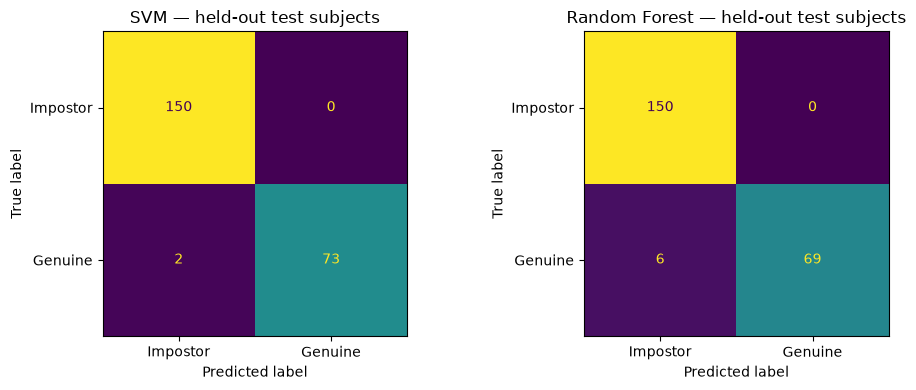

Report for BEST validation model:
              precision    recall  f1-score   support

    Impostor       0.99      1.00      0.99       150
     Genuine       1.00      0.97      0.99        75

    accuracy                           0.99       225
   macro avg       0.99      0.99      0.99       225
weighted avg       0.99      0.99      0.99       225



In [5]:
pred=finger_result['predictions']
fig,axs=plt.subplots(1,2,figsize=(10,4))
for ax,name in zip(axs,('SVM','Random Forest')):
    threshold=float(finger_result['comparison'].set_index('model').loc[name,'threshold'])
    yh=(pred['score_'+name].to_numpy()>=threshold).astype(int)
    cm=confusion_matrix(pred.label,yh,labels=[0,1])
    ConfusionMatrixDisplay(cm,display_labels=['Impostor','Genuine']).plot(ax=ax,colorbar=False)
    ax.set_title(name+' — held-out test subjects')
    print(name,'Confusion matrix: TN FP / FN TP =',cm.tolist())
plt.tight_layout();plt.savefig(OUT/'04_confusion_matrices.png',dpi=160);plt.show()
print('Report for BEST validation model:')
best=finger_result['best'];threshold=finger_result['threshold']
print(classification_report(pred.label,(pred['score_'+best]>=threshold).astype(int),
       target_names=['Impostor','Genuine'],zero_division=0))

## 6 — ROC, FAR/FRR comparison

ROC displays TPR against FPR as the decision threshold changes. The final selected threshold comes from **validation**, not a threshold optimized on test.

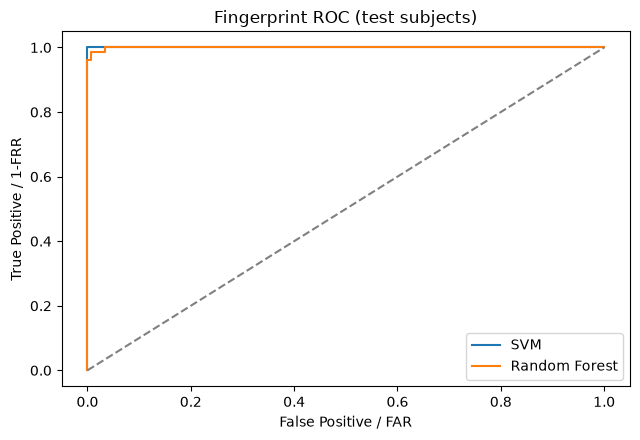

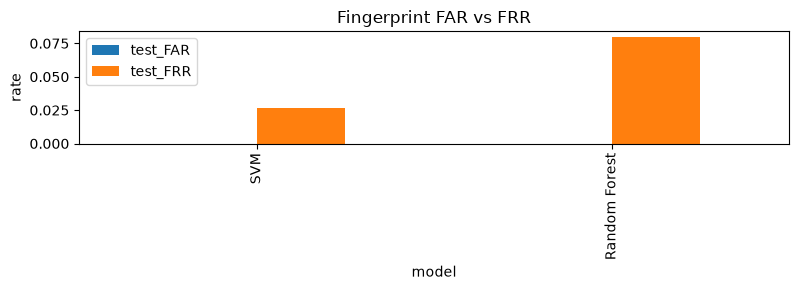

In [6]:
fig,ax=plt.subplots(figsize=(6.5,4.5))
for name in ('SVM','Random Forest'):
    fpr,tpr,_=roc_curve(pred.label,pred['score_'+name]);ax.plot(fpr,tpr,label=name)
ax.plot([0,1],[0,1],'--',c='grey');ax.set_xlabel('False Positive / FAR')
ax.set_ylabel('True Positive / 1-FRR');ax.set_title('Fingerprint ROC (test subjects)');ax.legend()
plt.tight_layout();plt.savefig(OUT/'05_roc.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(8,3))
tab=finger_result['comparison'].set_index('model')
tab[['test_FAR','test_FRR']].plot.bar(ax=ax);ax.set_ylabel('rate');ax.set_title('Fingerprint FAR vs FRR');plt.tight_layout()
plt.savefig(OUT/'06_far_frr.png',dpi=160);plt.show()

## 7 — OFFLINE Image Upload demonstration (not a real-time scanner)

Upload/select an image using its local file path and a **claimed fingerprint ID** for 1:1 verification; optional 1:N is for academic demonstration. The model gallery refers to **public SOCOFing sample fingers**, not employees registered in your game. A random picture is not a valid fingerprint. Test with a test-set altered image that was *not* used to fit the verifier.

In [7]:
pack=joblib.load(MODEL/'fingerprint_model.joblib')  # trusted locally produced model only
finger_id=next(iter(pack['demo_gallery']))
upload_path=fp_manifest[(fp_manifest.finger==finger_id)&(fp_manifest.kind=='altered')].iloc[0].path
print('Example upload image:',upload_path)
print('Known/claimed finger:',finger_id)
print('1-to-1 result:',fp.verify_upload(upload_path,claimed_finger=finger_id,model_path=str(MODEL/'fingerprint_model.joblib')))
print('Optional 1-to-N result:',fp.identify_upload(upload_path,model_path=str(MODEL/'fingerprint_model.joblib')))
# To test your own uploaded file AFTER training, uncomment and give a path:
# MY_UPLOAD = r'C:/Users/YOURNAME/Downloads/test_fingerprint.bmp'
# print(fp.verify_upload(MY_UPLOAD,claimed_finger=finger_id,model_path=str(MODEL/'fingerprint_model.joblib')))

Example upload image: fingerprint_data\selected\altered\88def586b7e3_00.png
Known/claimed finger: 319__m_right_middle_finger
1-to-1 result: {'match': True, 'score': 0.9948303941246431, 'threshold': 0.8077645335329597}
Optional 1-to-N result: {'match': True, 'finger': '319__m_right_middle_finger', 'score': 0.9948303941246431, 'threshold': 0.8077645335329597, 'compared_with': 25}


## 8 — Export audit, Flask interface and instructor Q&A

Final artifacts are created alongside original RAVDESS models in `model/`:

- `fingerprint_model.joblib` — winning **verification** model, acceptance threshold and test-split demo gallery
- `fingerprint_comparison.csv`, `fingerprint_test_predictions.csv`
- Plots under `outputs/fingerprint_bonus/`

**Flask:** add an **Offline Fingerprint Upload** view, *not* a requirement to open the Secret Door. Python import: `fingerprint_research.verify_upload(image_path, claimed_finger, model_path=...)`. Only load trusted locally trained model files, never a user-uploaded `.joblib` file.

**Explain aloud:** Sobel = edges/orientation; LBP = local binary texture pattern; FAR = false acceptance, FRR = false rejection; a finger is not a whole person; synthetic alterations do not equal new acquisitions.

In [8]:
print('Exported:')
for name in ['fingerprint_model.joblib','fingerprint_comparison.csv','fingerprint_test_predictions.csv']:
    p=MODEL/name;print(name,'OK' if p.exists() else 'MISSING',p.stat().st_size if p.exists() else '')
assert (MODEL/'fingerprint_model.joblib').exists()
print('Existing RAVDESS model stays untouched:',(MODEL/'public_models.joblib').exists())

Exported:
fingerprint_model.joblib OK 18611
fingerprint_comparison.csv OK 636
fingerprint_test_predictions.csv OK 20383
Existing RAVDESS model stays untouched: True
